# Mini-Prototipo: Evaluación Paralela de Fitness con Spark RDD

**Objetivo:** Validar que el paralelismo de Spark funciona correctamente para la evaluación distribuida de fitness de una población de cromosomas (individuos del GA).

**Qué se valida:**
1. Distribución de individuos como RDD y evaluación paralela con `map()`
2. Comparación de tiempos: ejecución secuencial (Python puro) vs. paralela (Spark RDD)
3. Observabilidad en la Spark Web UI (`http://localhost:4040`)
4. Correctitud: los resultados paralelos coinciden con los secuenciales

**Nota:** Se usa una función fitness dummy (simulada con `time.sleep`) para aislar el efecto del paralelismo sin depender del clasificador real.

---
## 1. Setup: Spark Session e Imports

In [1]:
import sys
sys.path.insert(0, '../src')

from spark_config import crear_sesion_spark, mostrar_info_spark, parar_spark
import numpy as np
import time
import math
from datetime import datetime

print(f"Notebook iniciado: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Notebook iniciado: 2026-02-21 19:42:26


In [2]:
spark = crear_sesion_spark(
    app_name="TFM_Prototipo_Paralelo",
    master="local[*]",
    driver_memory="4g",
    executor_memory="4g",
    ui_port=4040,
    verbose=False
)

sc = spark.sparkContext
mostrar_info_spark(spark, ui_port=4040)

NUM_CORES = sc.defaultParallelism
print(f"\nCores disponibles para paralelismo: {NUM_CORES}")

26/02/21 19:42:41 WARN Utils: Your hostname, Frans-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.64.1 instead (on interface bridge100)
26/02/21 19:42:41 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/02/21 19:42:41 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


🔥 INFORMACIÓN DE SPARK SESSION
✓ App Name: TFM_Prototipo_Paralelo
✓ Master: local[*]
✓ Spark Version: 3.5.0
✓ Python Version: 3.9
✓ Default Parallelism: 4
✓ Default Min Partitions: 2

🌐 SPARK WEB UI
📊 Accede en tu navegador a:
   👉 http://localhost:4040

   Opciones disponibles:
   - Jobs: Ver trabajos en ejecución/completados
   - Stages: Ver stages de cada job
   - Storage: Ver RDDs cacheados
   - Environment: Configuración de Spark
   - Executors: Estado de ejecutores


Cores disponibles para paralelismo: 4


---
## 2. Generación de la Población Ficticia

Cada individuo es un cromosoma binario de longitud $D$, representando un subconjunto candidato de características. Se genera una población de $P$ individuos con inicialización aleatoria ($p_{init} = 0.5$).

In [3]:
# Parámetros de la población
D = 30           # Dimensionalidad del cromosoma (como WDBC)
P = 100          # Tamaño de la población
P_INIT = 0.5     # Probabilidad de inicialización de cada gen

np.random.seed(42)
poblacion = [list(np.random.binomial(1, P_INIT, D)) for _ in range(P)]

print(f"Poblacion generada: {P} individuos, cromosoma de longitud {D}")
print(f"Ejemplo individuo[0]: {poblacion[0]}")
print(f"Genes activos en individuo[0]: {sum(poblacion[0])}/{D}")

Poblacion generada: 100 individuos, cromosoma de longitud 30
Ejemplo individuo[0]: [0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0]
Genes activos en individuo[0]: 13/30


---
## 3. Función Fitness Dummy

Se definen dos variantes de fitness simulado:

- **`fitness_rapido`**: Solo cálculo numérico (Rastrigin). Evalúa si Spark distribuye correctamente pero el overhead de serialización puede dominar.
- **`fitness_costoso`**: Incluye un `time.sleep()` para simular el coste real de entrenar un clasificador con cross-validation. Aquí es donde el paralelismo debe brillar.

Ambas siguen la fórmula del diseño: $\text{Fitness}(\mathbf{c}) = \alpha \cdot \text{Score}(\mathbf{c}) - \beta \cdot \frac{|S|}{D}$

In [4]:
ALPHA = 0.9
BETA = 0.1

def fitness_rapido(cromosoma):
    """Fitness basado en la función Rastrigin (solo cálculo, sin sleep)."""
    genes_activos = sum(cromosoma)
    d = len(cromosoma)
    if genes_activos == 0:
        return 0.0
    # Rastrigin invertida y normalizada como pseudo-accuracy
    A = 10
    rastrigin = A * genes_activos
    for i, gen in enumerate(cromosoma):
        if gen == 1:
            x = (i / d) * 2 - 1  # mapear a [-1, 1]
            rastrigin += x**2 - A * math.cos(2 * math.pi * x)
    score = 1.0 / (1.0 + rastrigin)  # normalizar a [0, 1]
    penalizacion = genes_activos / d
    return round(ALPHA * score - BETA * penalizacion, 6)


def fitness_costoso(cromosoma, sleep_ms=50):
    """Fitness con sleep simulando coste de entrenamiento de clasificador."""
    time.sleep(sleep_ms / 1000.0)  # Simular coste computacional
    return fitness_rapido(cromosoma)


# Test rápido
test_cromosoma = poblacion[0]
print(f"Fitness rapido individuo[0]: {fitness_rapido(test_cromosoma):.6f}")
print(f"Genes activos: {sum(test_cromosoma)}/{D}")

Fitness rapido individuo[0]: -0.036726
Genes activos: 13/30


---
## 4. Evaluación Secuencial (Baseline)

Evaluamos toda la población con Python puro (un solo hilo) para tener un baseline de tiempo.

In [5]:
SLEEP_MS = 50  # ms por evaluación (simula coste de 5-fold CV con GNB)

print(f"=" * 60)
print(f"EVALUACION SECUENCIAL (Python puro)")
print(f"Poblacion: {P} individuos | Sleep por eval: {SLEEP_MS}ms")
print(f"Tiempo estimado: {P * SLEEP_MS / 1000:.1f}s")
print(f"=" * 60)

inicio_seq = time.time()
fitness_seq = [fitness_costoso(ind, sleep_ms=SLEEP_MS) for ind in poblacion]
tiempo_seq = time.time() - inicio_seq

print(f"\nTiempo secuencial: {tiempo_seq:.2f}s")
print(f"Mejor fitness: {max(fitness_seq):.6f}")
print(f"Fitness medio: {np.mean(fitness_seq):.6f}")
print(f"Peor fitness:  {min(fitness_seq):.6f}")

EVALUACION SECUENCIAL (Python puro)
Poblacion: 100 individuos | Sleep por eval: 50ms
Tiempo estimado: 5.0s

Tiempo secuencial: 5.42s
Mejor fitness: -0.018991
Fitness medio: -0.044570
Peor fitness:  -0.065968


---
## 5. Evaluación Paralela con Spark RDD

La población se distribuye como un RDD y cada individuo se evalúa en paralelo con `rdd.map()`. Este es el patrón exacto que usará el GA real:

```python
fitness_scores = RDD(poblacion).map(evaluar_fitness).collect()
```

**Puntos a observar en la Web UI (`http://localhost:4040`):**
- Pestaña **Jobs**: aparecerá un job por cada `.collect()`
- Pestaña **Stages**: ver cuántas tareas se ejecutan en paralelo
- Pestaña **Executors**: uso de CPU y memoria

In [6]:
print(f"=" * 60)
print(f"EVALUACION PARALELA (Spark RDD)")
print(f"Poblacion: {P} individuos | Particiones: {NUM_CORES}")
print(f"Sleep por eval: {SLEEP_MS}ms")
print(f"Tiempo estimado: ~{P * SLEEP_MS / 1000 / NUM_CORES:.1f}s ({NUM_CORES} cores)")
print(f"=" * 60)
print(f"\n>>> Abre http://localhost:4040 para observar la ejecucion <<<\n")

# Distribuir población como RDD
rdd_poblacion = sc.parallelize(poblacion, numSlices=NUM_CORES)

# Evaluación paralela
inicio_par = time.time()
fitness_par = rdd_poblacion.map(lambda ind: fitness_costoso(ind, sleep_ms=SLEEP_MS)).collect()
tiempo_par = time.time() - inicio_par

print(f"Tiempo paralelo:  {tiempo_par:.2f}s")
print(f"Mejor fitness: {max(fitness_par):.6f}")
print(f"Fitness medio: {np.mean(fitness_par):.6f}")
print(f"Peor fitness:  {min(fitness_par):.6f}")

EVALUACION PARALELA (Spark RDD)
Poblacion: 100 individuos | Particiones: 4
Sleep por eval: 50ms
Tiempo estimado: ~1.2s (4 cores)

>>> Abre http://localhost:4040 para observar la ejecucion <<<



Tiempo paralelo:  1.99s
Mejor fitness: -0.018991
Fitness medio: -0.044570
Peor fitness:  -0.065968


---
## 6. Comparación y Validación

In [7]:
# Validación de correctitud: resultados secuenciales == paralelos
resultados_iguales = all(
    abs(s - p) < 1e-9 for s, p in zip(fitness_seq, fitness_par)
)

speedup = tiempo_seq / tiempo_par
eficiencia = speedup / NUM_CORES * 100

print(f"=" * 60)
print(f"RESULTADOS")
print(f"=" * 60)
print(f"Tiempo secuencial:  {tiempo_seq:.2f}s")
print(f"Tiempo paralelo:    {tiempo_par:.2f}s")
print(f"Speedup:            {speedup:.2f}x")
print(f"Cores utilizados:   {NUM_CORES}")
print(f"Eficiencia:         {eficiencia:.1f}%")
print(f"Correctitud (seq == par): {'OK' if resultados_iguales else 'FALLO'}")
print(f"=" * 60)

if speedup > 1.5:
    print(f"\nCONCLUSION: El paralelismo funciona. Speedup de {speedup:.2f}x con {NUM_CORES} cores.")
else:
    print(f"\nAVISO: Speedup bajo ({speedup:.2f}x). Revisar configuracion de Spark.")

RESULTADOS
Tiempo secuencial:  5.42s
Tiempo paralelo:    1.99s
Speedup:            2.73x
Cores utilizados:   4
Eficiencia:         68.2%
Correctitud (seq == par): OK

CONCLUSION: El paralelismo funciona. Speedup de 2.73x con 4 cores.


---
## 7. Experimento: Escalabilidad por Número de Particiones

Variamos el número de particiones del RDD para observar cómo afecta al speedup. Cada partición se procesa como una tarea independiente en Spark.

In [8]:
particiones_test = [1, 2, 4, NUM_CORES, NUM_CORES * 2]
# Eliminar duplicados y ordenar
particiones_test = sorted(set(particiones_test))

resultados_escalabilidad = []

print(f"Experimento de escalabilidad (P={P}, sleep={SLEEP_MS}ms)")
print(f"-" * 50)

for n_part in particiones_test:
    rdd = sc.parallelize(poblacion, numSlices=n_part)
    inicio = time.time()
    rdd.map(lambda ind: fitness_costoso(ind, sleep_ms=SLEEP_MS)).collect()
    t = time.time() - inicio
    sp = tiempo_seq / t
    resultados_escalabilidad.append({
        'particiones': n_part,
        'tiempo_s': round(t, 2),
        'speedup': round(sp, 2)
    })
    print(f"  Particiones={n_part:>3d} | Tiempo={t:.2f}s | Speedup={sp:.2f}x")

print(f"-" * 50)
print(f"  Baseline secuencial: {tiempo_seq:.2f}s")

Experimento de escalabilidad (P=100, sleep=50ms)
--------------------------------------------------


  Particiones=  1 | Tiempo=5.14s | Speedup=1.05x


  Particiones=  2 | Tiempo=2.58s | Speedup=2.10x


  Particiones=  4 | Tiempo=1.30s | Speedup=4.17x
  Particiones=  8 | Tiempo=0.85s | Speedup=6.39x
--------------------------------------------------
  Baseline secuencial: 5.42s


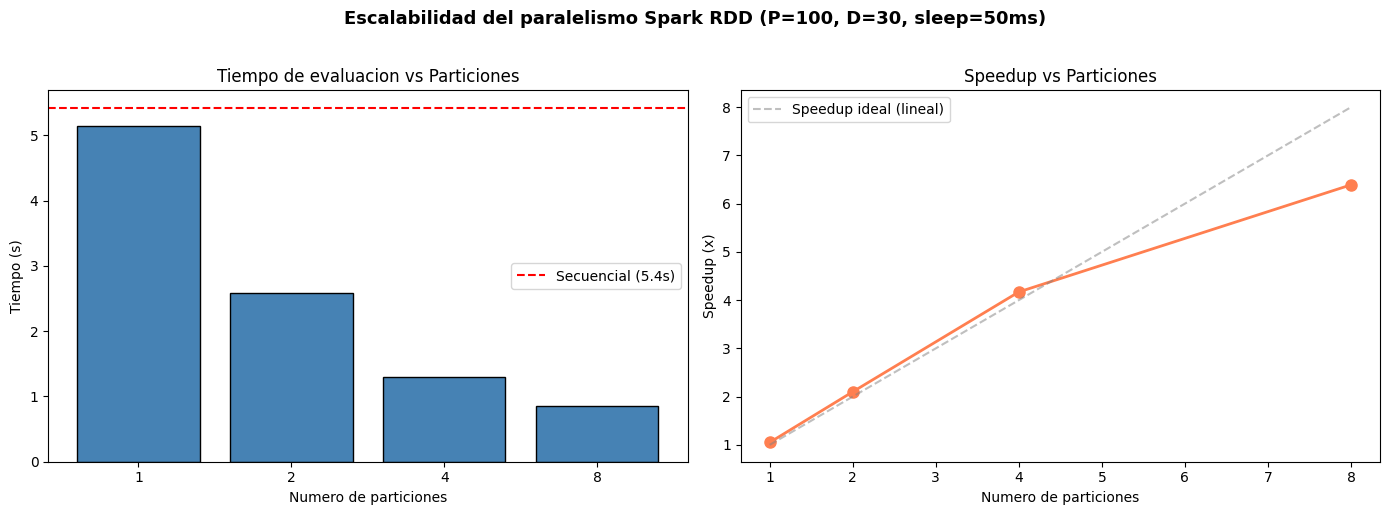

Grafico guardado en results/escalabilidad_paralela.png


In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

parts = [r['particiones'] for r in resultados_escalabilidad]
tiempos = [r['tiempo_s'] for r in resultados_escalabilidad]
speedups = [r['speedup'] for r in resultados_escalabilidad]

# Grafico 1: Tiempo vs Particiones
axes[0].bar(range(len(parts)), tiempos, color='steelblue', edgecolor='black')
axes[0].axhline(y=tiempo_seq, color='red', linestyle='--', label=f'Secuencial ({tiempo_seq:.1f}s)')
axes[0].set_xticks(range(len(parts)))
axes[0].set_xticklabels(parts)
axes[0].set_xlabel('Numero de particiones')
axes[0].set_ylabel('Tiempo (s)')
axes[0].set_title('Tiempo de evaluacion vs Particiones')
axes[0].legend()

# Grafico 2: Speedup vs Particiones
axes[1].plot(parts, speedups, 'o-', color='coral', linewidth=2, markersize=8)
axes[1].plot(parts, parts, '--', color='gray', alpha=0.5, label='Speedup ideal (lineal)')
axes[1].set_xlabel('Numero de particiones')
axes[1].set_ylabel('Speedup (x)')
axes[1].set_title('Speedup vs Particiones')
axes[1].legend()

plt.suptitle(f'Escalabilidad del paralelismo Spark RDD (P={P}, D={D}, sleep={SLEEP_MS}ms)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/escalabilidad_paralela.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/escalabilidad_paralela.png")

---
## 8. Simulación de una Generación Completa del GA

Para validar el patrón completo, simulamos una generación del ciclo evolutivo:
1. Evaluar fitness en paralelo (Spark)
2. Selección por torneo
3. Cruce y mutación
4. Nueva generación

In [10]:
import random
random.seed(42)

P_CROSS = 0.8
P_MUT = 0.2
P_MUT_BIT = 1 / D  # ~0.033 para D=30
ELITE_SIZE = 2

def torneo_binario(poblacion, fitness_scores):
    """Seleccion por torneo de tamano 2."""
    i, j = random.sample(range(len(poblacion)), 2)
    if fitness_scores[i] >= fitness_scores[j]:
        return list(poblacion[i])
    return list(poblacion[j])

def cruce_un_punto(padre1, padre2):
    """Cruce de un punto."""
    punto = random.randint(1, len(padre1) - 1)
    hijo1 = padre1[:punto] + padre2[punto:]
    hijo2 = padre2[:punto] + padre1[punto:]
    return hijo1, hijo2

def mutacion_flip(cromosoma, p_mut_bit):
    """Mutacion por inversion de bit."""
    return [1 - gen if random.random() < p_mut_bit else gen for gen in cromosoma]

def una_generacion(poblacion, fitness_scores):
    """Ejecuta una generacion completa del GA."""
    # Elitismo: preservar top-E
    indices_elite = sorted(range(len(fitness_scores)),
                           key=lambda i: fitness_scores[i], reverse=True)[:ELITE_SIZE]
    elite = [list(poblacion[i]) for i in indices_elite]

    # Generar descendencia
    descendencia = []
    while len(descendencia) < P - ELITE_SIZE:
        padre1 = torneo_binario(poblacion, fitness_scores)
        padre2 = torneo_binario(poblacion, fitness_scores)

        # Cruce
        if random.random() < P_CROSS:
            hijo1, hijo2 = cruce_un_punto(padre1, padre2)
        else:
            hijo1, hijo2 = list(padre1), list(padre2)

        # Mutacion
        if random.random() < P_MUT:
            hijo1 = mutacion_flip(hijo1, P_MUT_BIT)
        if random.random() < P_MUT:
            hijo2 = mutacion_flip(hijo2, P_MUT_BIT)

        descendencia.extend([hijo1, hijo2])

    return elite + descendencia[:P - ELITE_SIZE]


print("Operadores geneticos definidos.")
print(f"  Cruce: un punto (p_cross={P_CROSS})")
print(f"  Mutacion: flip bit (p_mut={P_MUT}, p_mut_bit={P_MUT_BIT:.4f})")
print(f"  Elitismo: top {ELITE_SIZE}")

Operadores geneticos definidos.
  Cruce: un punto (p_cross=0.8)
  Mutacion: flip bit (p_mut=0.2, p_mut_bit=0.0333)
  Elitismo: top 2


In [11]:
NUM_GENERACIONES = 5
SLEEP_GEN = 20  # ms por eval (mas rapido para no esperar mucho)

print(f"Simulacion de {NUM_GENERACIONES} generaciones del GA")
print(f"P={P}, D={D}, sleep={SLEEP_GEN}ms/eval")
print(f">>> Observa los jobs en http://localhost:4040 <<<\n")

pop = list(poblacion)  # copia
historico_mejor = []
historico_medio = []
tiempos_gen = []

for gen in range(NUM_GENERACIONES):
    t0 = time.time()

    # Paso 1: Evaluacion paralela con Spark
    rdd_pop = sc.parallelize(pop, numSlices=NUM_CORES)
    scores = rdd_pop.map(lambda ind: fitness_costoso(ind, sleep_ms=SLEEP_GEN)).collect()

    mejor = max(scores)
    medio = np.mean(scores)
    historico_mejor.append(mejor)
    historico_medio.append(medio)

    # Paso 2: Operadores geneticos (secuencial, rapido)
    pop = una_generacion(pop, scores)

    t_gen = time.time() - t0
    tiempos_gen.append(t_gen)

    print(f"  Gen {gen+1:>2d}/{NUM_GENERACIONES} | "
          f"Mejor={mejor:.6f} | Media={medio:.6f} | "
          f"Tiempo={t_gen:.2f}s")

print(f"\nTiempo total: {sum(tiempos_gen):.2f}s")
print(f"Tiempo medio por generacion: {np.mean(tiempos_gen):.2f}s")

Simulacion de 5 generaciones del GA
P=100, D=30, sleep=20ms/eval
>>> Observa los jobs en http://localhost:4040 <<<

  Gen  1/5 | Mejor=-0.018991 | Media=-0.044570 | Tiempo=0.57s
  Gen  2/5 | Mejor=-0.013907 | Media=-0.039864 | Tiempo=0.56s
  Gen  3/5 | Mejor=-0.013907 | Media=-0.034355 | Tiempo=0.55s


  Gen  4/5 | Mejor=-0.006634 | Media=-0.030080 | Tiempo=0.56s
  Gen  5/5 | Mejor=0.003943 | Media=-0.023833 | Tiempo=0.56s

Tiempo total: 2.80s
Tiempo medio por generacion: 0.56s


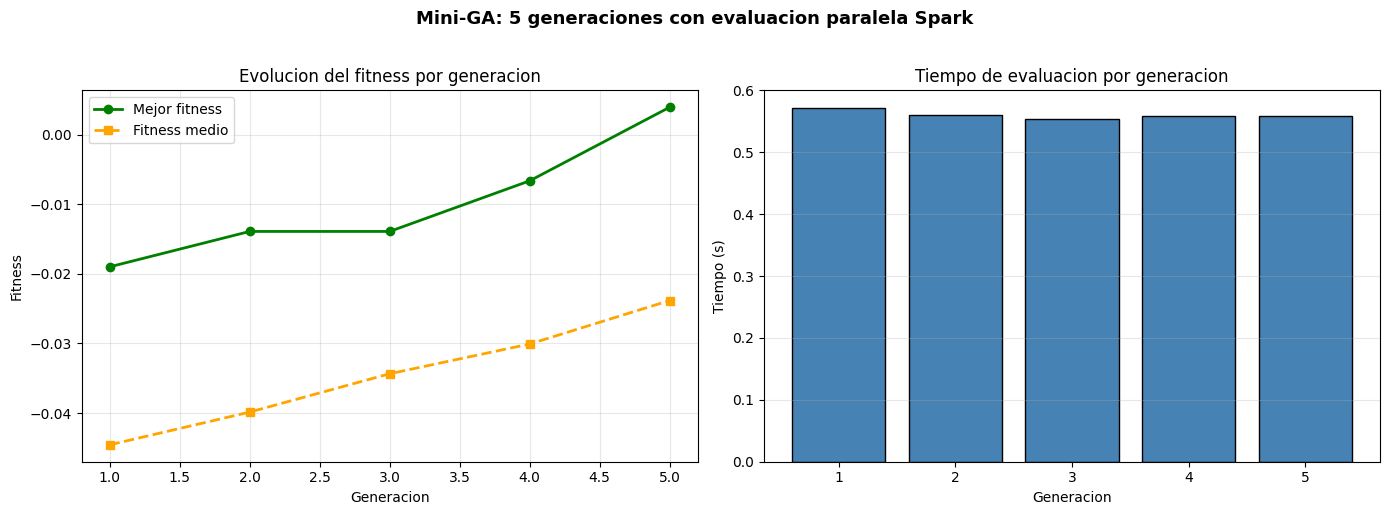

Grafico guardado en results/mini_ga_generaciones.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gens = range(1, NUM_GENERACIONES + 1)

# Grafico 1: Evolucion del fitness
axes[0].plot(gens, historico_mejor, 'o-', color='green', linewidth=2, label='Mejor fitness')
axes[0].plot(gens, historico_medio, 's--', color='orange', linewidth=2, label='Fitness medio')
axes[0].set_xlabel('Generacion')
axes[0].set_ylabel('Fitness')
axes[0].set_title('Evolucion del fitness por generacion')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Grafico 2: Tiempo por generacion
axes[1].bar(gens, tiempos_gen, color='steelblue', edgecolor='black')
axes[1].set_xlabel('Generacion')
axes[1].set_ylabel('Tiempo (s)')
axes[1].set_title('Tiempo de evaluacion por generacion')
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle(f'Mini-GA: {NUM_GENERACIONES} generaciones con evaluacion paralela Spark',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/mini_ga_generaciones.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/mini_ga_generaciones.png")

---
## 9. Resumen de Validación

Este prototipo valida los siguientes puntos clave para el TFM:

In [13]:
print("=" * 60)
print("RESUMEN DE VALIDACION DEL PROTOTIPO")
print("=" * 60)

checks = [
    ("Poblacion distribuida como RDD", True),
    ("Evaluacion paralela con rdd.map()", True),
    ("Resultados seq == paralelo (correctitud)", resultados_iguales),
    (f"Speedup > 1.5x (obtenido: {speedup:.2f}x)", speedup > 1.5),
    ("Ciclo evolutivo completo ejecutado", len(historico_mejor) == NUM_GENERACIONES),
    ("Observable en Spark Web UI (localhost:4040)", True),
]

all_ok = True
for descripcion, ok in checks:
    estado = "PASS" if ok else "FAIL"
    print(f"  [{estado}] {descripcion}")
    if not ok:
        all_ok = False

print("=" * 60)
if all_ok:
    print("CONCLUSION: Paralelismo Spark validado. Listo para implementacion real.")
else:
    print("ATENCION: Hay validaciones fallidas. Revisar antes de continuar.")
print("=" * 60)

RESUMEN DE VALIDACION DEL PROTOTIPO
  [PASS] Poblacion distribuida como RDD
  [PASS] Evaluacion paralela con rdd.map()
  [PASS] Resultados seq == paralelo (correctitud)
  [PASS] Speedup > 1.5x (obtenido: 2.73x)
  [PASS] Ciclo evolutivo completo ejecutado
  [PASS] Observable en Spark Web UI (localhost:4040)
CONCLUSION: Paralelismo Spark validado. Listo para implementacion real.


In [14]:
parar_spark(spark)

✓ Spark session detenida
